# Data to discoveries

Last time, we discussed the `NumPy` array, specifically `ndarray`. 

These are like lists in that they contain data, but an `ndarray` carries many different assumptions/restrictions.

Today, we will use two important Python packages:
- `pandas` : data wrangling 
- `MatplotLib` : data visualisation

Both are widely used with large communities.

In [ ]:
import pandas as pd
print(f"pandas version: {pd.__version__}")

## Pandas DataFrame

A `DataFrame` in pandas is a data structure that is a mix between:
- Python's `dict`
- NumPy's `ndarray`

The following data comes from CSO's 2022 census data on car ownership. (I got this data from CSO a few years ago, but now I cannot reproduce this.)

In [ ]:
# Numbers come from counties: Cork, Dublin, Fingal, Galway, Sligo
car_ownership = {
    "Population": [360152, 592713, 330506, 193323, 70198],
    "No cars": [10335, 69661, 10371, 5033, 3350],
    "One car": [44419, 84685, 44495, 23406, 10422],
    "Two cars": [50310, 34861, 36562, 27542, 9055],
    "Three cars": [11243, 6129, 6368, 5593, 1676],
    "Four or more cars": [4908, 1736, 1933, 2291, 567],
}

In [ ]:
print(car_ownership["Population"])
print(car_ownership["Population"][3])	# Population of Galway in 2022

This way of indexing is similar to how one does indexing for a `DataFrame`.

In [ ]:
df = pd.DataFrame(		# 'df' is a standard variable for a DataFrame
	car_ownership, 
	index=["Cork", "Dublin", "Fingal", "Galway", "Sligo"]
)
df

All `DataFrame`s have an `Index` which is the leftmost column. Default: `[0, 1, 2, ...]`

Think of a `DataFrame` as a spreadsheet, a table of data, and/or a collection of columns.

Each column is a `NumPy` array -- *therefore* each column has a **fixed** data type.

Different columns can have different data types (we will see examples soon).

In [ ]:
df["Population"]		# Grab a column

In [ ]:
df.loc["Galway"]		# Grab a row

In [ ]:
print(df["Population"]["Galway"])
# Notice the NumPy type in the output:
df["Population"]["Galway"] == df.loc["Galway"]["Population"]	

## UN's SDG data for Ireland

Let's load in UN data about Ireland from two files sources: 
- `data/01_below_poverty.csv`
- `data/06_sage_drinking_water.csv`
- `data/07_renewable_energy.csv`
- `data/08_NEET.csv`

This was obtained from the [United Nations' SDG Country Profile Page](https://unstats.un.org/sdgs/dataportal/countryprofiles/IRL)

### Below Poverty Data Set

We'll work through some of the basics with the below poverty data set.

Best way to get data into `pandas` is to use one of the many `pd.read_...` functions.

In [52]:
df1 = pd.read_csv("data/01_below_poverty.csv")		# CSV to pandas DataFrame
df1.head()											# Display first 5 rows

,Goal,Target,Indicator,SeriesCode,SeriesDescription,GeoAreaCode,GeoAreaName,TimePeriod,Value,Time_Detail,...,BasePeriod,Source,GeoInfoUrl,FootNote,[Age],[Location],[Nature],[Reporting Type],[Sex],[Units]
0,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1987,1.3,1987,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from SI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
1,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1994,0.4,1994,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
2,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1995,0.4,1995,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
3,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,1996,0.2,1996,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT
4,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,372,Ireland,2000,0.2,2000,...,2021,"Poverty and Inequality Portal, World Bank",NaN,"Accessed March 24, 2026. Based on data from LI...",ALLAGE,ALLAREA,G,G,BOTHSEX,PERCENT


Most of the columns look irrelevant. Let's look to keep the columns
- "TimePeriod"
- "Value"
- "Time_Detail"
- "[Age]"
- "[Location]"
- "[Sex]"

We'll select relevant columns by indexing with a list of column names.

In [53]:
df1 = df1[[
	"TimePeriod",
	"Value",
	"Time_Detail",
	"[Age]",
	"[Location]",
	"[Sex]"
]]
df1

,TimePeriod,Value,Time_Detail,[Age],[Location],[Sex]
0,1987,1.30000,1987,ALLAGE,ALLAREA,BOTHSEX
1,1994,0.40000,1994,ALLAGE,ALLAREA,BOTHSEX
2,1995,0.40000,1995,ALLAGE,ALLAREA,BOTHSEX
3,1996,0.20000,1996,ALLAGE,ALLAREA,BOTHSEX
4,2000,0.20000,2000,ALLAGE,ALLAREA,BOTHSEX
...,...,...,...,...,...,...
155,2022,0.11242,2022,ALLAGE,URBAN,BOTHSEX
156,2022,0.16275,2022,ALLAGE,ALLAREA,FEMALE
157,2022,0.23991,2022,ALLAGE,ALLAREA,MALE
158,2022,0.34032,2022,ALLAGE,RURAL,BOTHSEX


It's weird that `"TimePeriod"` is a float. Let's change this to an int.

In [54]:
df1.astype({"TimePeriod" : "i"})

,TimePeriod,Value,Time_Detail,[Age],[Location],[Sex]
0,1987,1.30000,1987,ALLAGE,ALLAREA,BOTHSEX
1,1994,0.40000,1994,ALLAGE,ALLAREA,BOTHSEX
2,1995,0.40000,1995,ALLAGE,ALLAREA,BOTHSEX
3,1996,0.20000,1996,ALLAGE,ALLAREA,BOTHSEX
4,2000,0.20000,2000,ALLAGE,ALLAREA,BOTHSEX
...,...,...,...,...,...,...
155,2022,0.11242,2022,ALLAGE,URBAN,BOTHSEX
156,2022,0.16275,2022,ALLAGE,ALLAREA,FEMALE
157,2022,0.23991,2022,ALLAGE,ALLAREA,MALE
158,2022,0.34032,2022,ALLAGE,RURAL,BOTHSEX


We need to clean our data before we can manipulate it. Let's remove the rows where `"TimePeriod"` is empty.

In [55]:
df1 = df1.dropna(subset="TimePeriod")
df1 = df1.astype({"TimePeriod" : "i"})
df1.loc[22]

TimePeriod        2005
Value          0.23595
Time_Detail       2005
[Age]              65+
[Location]     ALLAREA
[Sex]          BOTHSEX
Name: 22, dtype: object

We are not going to span the entirity of this data set. Let's just take the years 2005 to 2023.

We'll do this with the [query](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.query.html) command. 

At a basic level it takes a string that appropriately masks part of the dataframe.

By default, `query` is a copy, unlike slicing in `ndarray` which yields a view.

In [56]:
df1 = df1.query("2005 <= TimePeriod <= 2023")

# Now more clean up
df1 = df1.drop(["Time_Detail"], axis=1)			# Useless column

df1

,TimePeriod,Value,[Age],[Location],[Sex]
22,2005,0.23595,65+,ALLAREA,BOTHSEX
23,2005,0.10000,ALLAGE,ALLAREA,BOTHSEX
24,2005,0.03954,<15Y,ALLAREA,BOTHSEX
25,2005,0.04021,15-64,ALLAREA,BOTHSEX
26,2005,0.04332,ALLAGE,ALLAREA,FEMALE
...,...,...,...,...,...
155,2022,0.11242,ALLAGE,URBAN,BOTHSEX
156,2022,0.16275,ALLAGE,ALLAREA,FEMALE
157,2022,0.23991,ALLAGE,ALLAREA,MALE
158,2022,0.34032,ALLAGE,RURAL,BOTHSEX


Now we are going to remove rows we don't have any need for; we give two equivalent ways to do this.

We'll use `query` again to obtain only the rows that are relevant.

In [57]:
# df1 = df1[
# 	(df1["[Age]"] == "ALLAGE") & 
# 	(df1["[Location]"] == "ALLAREA") &
# 	(df1["[Sex]"] == "BOTHSEX")
# ]
df1 = (df1
    .query("`[Age]` == 'ALLAGE'")
    .query("`[Location]` == 'ALLAREA'")
    .query("`[Sex]` == 'BOTHSEX'")
)
df1

,TimePeriod,Value,[Age],[Location],[Sex]
23,2005,0.1,ALLAGE,ALLAREA,BOTHSEX
37,2006,0.5,ALLAGE,ALLAREA,BOTHSEX
38,2007,0.1,ALLAGE,ALLAREA,BOTHSEX
53,2008,0.2,ALLAGE,ALLAREA,BOTHSEX
54,2009,0.6,ALLAGE,ALLAREA,BOTHSEX
69,2010,0.7,ALLAGE,ALLAREA,BOTHSEX
70,2011,0.7,ALLAGE,ALLAREA,BOTHSEX
85,2012,0.5,ALLAGE,ALLAREA,BOTHSEX
86,2013,0.7,ALLAGE,ALLAREA,BOTHSEX
101,2014,0.4,ALLAGE,ALLAREA,BOTHSEX


Some final touches.

In [58]:
df1 = df1.drop(["[Age]", "[Location]", "[Sex]"], axis=1)
df1 = df1.set_index("TimePeriod")
df1 = df1.rename(columns={"Value" : "Below Poverty (%)"})
df1

,Below Poverty (%)
TimePeriod,
2005,0.1
2006,0.5
2007,0.1
2008,0.2
2009,0.6
2010,0.7
2011,0.7
2012,0.5
2013,0.7


### Speedrun the rest

We will basically do the same steps as above, but all at once. See if you can follow along line by line.

In [59]:
df2 = pd.read_csv("data/07_renewable_energy.csv")
df2 = df2[["TimePeriod", "Value"]]
df2 = df2.dropna()
df2 = df2.astype({"TimePeriod" : "i"})
df2 = df2.set_index("TimePeriod")
df2 = df2.loc["2005":"2023"]
df2 = df2.rename(columns={"Value" : "Renewable Energy Share (%)"})
df2

,Renewable Energy Share (%)
TimePeriod,
2005,2.90
2006,3.28
2007,3.56
2008,4.21
2009,5.32
2010,5.31
2011,7.00
2012,6.94
2013,7.76


In [73]:
df3 = pd.read_csv("data/06_safe_drinking_water.csv")
df3 = df3[["TimePeriod", "Value", "[Location]"]]
df3 = df3.dropna()
df3 = df3.astype({"TimePeriod" : "i"})
df3 = df3.set_index("TimePeriod")
df3 = df3.loc["2005":"2023"]
df3 = df3.query("`[Location]` == 'ALLAREA'")
df3 = df3.drop("[Location]", axis=1)
df3 = df3.rename(columns={"Value" : "Safe Drinking Water by Pop. (%)"})
df3

,Safe Drinking Water by Pop. (%)
TimePeriod,
2005,76.994415
2006,78.189987
2007,79.358139
2008,80.515526
2009,81.662399
2010,82.798592
2011,83.924301
2012,85.039505
2013,86.144142


In [77]:
df4 = pd.read_csv("data/08_NEET.csv")
df4 = df4[["TimePeriod", "Value", "[Sex]"]]
df4 = df4.dropna()
df4 = df4.astype({"TimePeriod" : "i"})
df4 = df4.set_index("TimePeriod")
df4 = df4.loc["2005":"2024"]
df4 = df4.query("`[Sex]` == 'BOTHSEX'")
df4 = df4.drop("[Sex]", axis=1)
df4 = df4.rename(columns={"Value" : "NEETs aged 15-24 (%)"})
df4

,NEETs aged 15-24 (%)
TimePeriod,
2005,10.53
2006,9.40
2007,10.07
2008,12.52
2009,18.30
2010,19.45
2011,19.16
2012,19.20
2013,16.44


## From two to one

Because our two DataFrames have the same index, we can concatenate them in `pandas`.

In [78]:
df = pd.concat([df1, df2, df3, df4], axis=1)		# Merging our two DataFrames
df.index.names = ["Year"]							# Renaming the index
df

,Below Poverty (%),Renewable Energy Share (%),Safe Drinking Water by Pop. (%),NEETs aged 15-24 (%)
Year,,,,
2005,0.1,2.90,76.994415,10.53
2006,0.5,3.28,78.189987,9.40
2007,0.1,3.56,79.358139,10.07
2008,0.2,4.21,80.515526,12.52
2009,0.6,5.32,81.662399,18.30
2010,0.7,5.31,82.798592,19.45
2011,0.7,7.00,83.924301,19.16
2012,0.5,6.94,85.039505,19.20
2013,0.7,7.76,86.144142,16.44


We can get some quick statistics on our data.

Using the `describe` method, we get the average and standard deviations.

In [82]:
df.describe()

,Below Poverty (%),Renewable Energy Share (%),Safe Drinking Water by Pop. (%),NEETs aged 15-24 (%)
count,19.000000,19.000000,19.000000,20.00000
mean,0.331579,8.603684,87.263798,12.25350
std,0.226207,3.996609,6.237695,4.56363
min,0.100000,2.900000,76.994415,5.07000
25%,0.100000,5.315000,82.230495,9.90250
50%,0.300000,8.670000,87.238304,11.54000
75%,0.500000,11.650000,93.400612,15.57750
max,0.700000,16.400000,95.626602,19.45000


#### Detour: visualization

We can now plot the DataFrame on a set of axes with `Matplotlib` (working in the background).

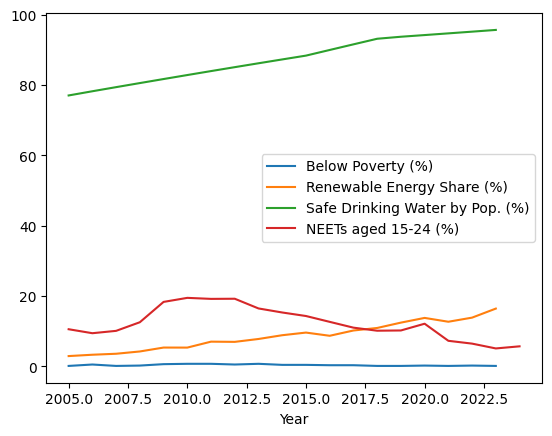

In [85]:
_ = df.plot()	# Not great

[Matplotlib](https://matplotlib.org/) is a wonderful data visualisation package built on top of NumPy.

`pandas` is built on top of `Matplotlib`, and one can easily interact via `df.plot(...)`. 

I personally like to work directly with `Matplotlib`.

Let's look at all of the data we have here between 2005 and 2023.

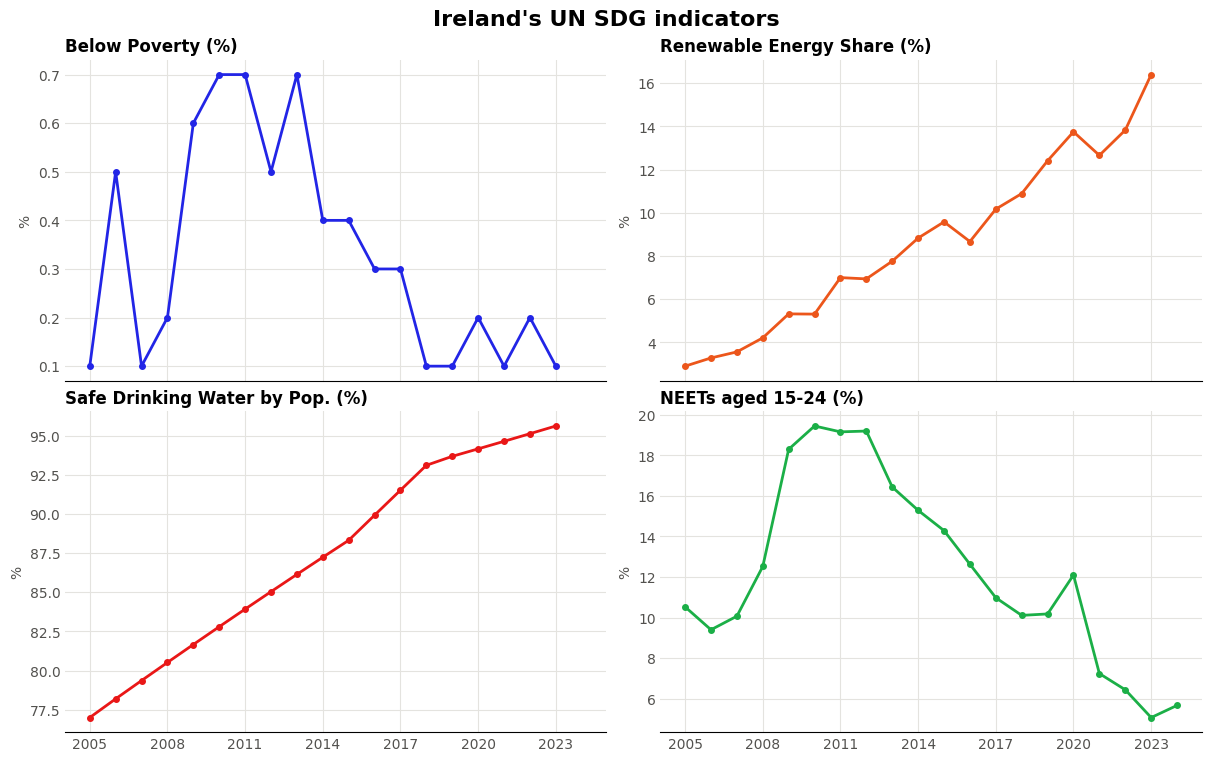

In [ ]:
import matplotlib.pyplot as plt

COLOURS = ["#2225e6", "#ec561b", "#e91717", "#1baf47"]	
MUTED = "#52514e"		# secondary text
GRID = "#e4e3df"		# faint gridlines

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, layout="constrained")
fig.suptitle("Ireland's UN SDG indicators", fontsize=16, fontweight="bold")

for ax, col, colour in zip(axes.flat, df.columns, COLOURS):
	s = df[col]
	ax.plot(s.index, s.values, color=colour, linewidth=2, marker="o", markersize=4)

	# Random settings to change the appearance. 
	ax.set_title(col, loc="left", fontsize=12, fontweight="bold")
	ax.grid(color=GRID, linewidth=0.8)	# horizontal and vertical gridlines
	ax.set_axisbelow(True)
	ax.spines[["top", "right", "left"]].set_visible(False)
	ax.tick_params(colors=MUTED, length=0)
	ax.set_ylabel("%", color=MUTED)
	ax.set_xticks(range(2005, 2024, 3))	# 2005, 2008, ..., 2023

plt.show()